<table border=0 width="100%"><tr><td><font size=5><B>week04-homework-api-data</B></font></td></tr></table>

# 第四周作业：选择1家上市公司并结合tushare获取数据进行分析
- 自由选择1家感兴趣的上市公司；
- 针对你选择的公司，提出一个你感兴趣的问题；
- 应用tushare获取与该公司相关的数据（不限于股市价格数据、财务等数据，国家宏观等数据均可使用）；
- 尝试应用你采集的数据做数据分析，回答你提出的问题。


提交作业：
- 在线提交：http://swufe.fanya.chaoxing.com/portal
- 截止日期：2026年10月16日晚上8点
- 提交**这个jupyter文档**，命名为“week04-homework-api-data_学号_姓名.ipynb”，学号姓名替换为自己的学号和姓名
- jupyter文档你要完成的包括四部分：公司名称与基本简介、研究问题题目及其内涵介绍、数据采集、数据分析与问题解答
- 为了批改方便，我这里将tushare token直接放到代码中

# 第一部分：公司名称与基本简介

内蒙古伊利实业集团股份有限公司（股票代码：600887.SH）是中国规模最大、产品线最全的乳制品企业，总部位于内蒙古呼和浩特。公司主营业务涵盖液体乳、奶粉及奶制品、冷饮产品等，旗下拥有“金典”“安慕希”“优酸乳”“畅轻”等多个知名品牌。

伊利是中国乳制品行业的绝对龙头，在液态奶市场占有率长期位居第一。截至2026年10月9日，公司总市值约1749.59亿元，总股本63.25亿股，流通股本62.94亿股，静态市盈率约15.13倍。2025年全年实现净利润115.65亿元，2026年上半年净利润57.59亿元。作为A股消费板块的核心资产之一，伊利被市场视为“乳业茅”，其经营状况和财务数据对理解中国乳制品消费趋势具有重要参考意义。

选择伊利，一方面是因为它和每个人的日常生活息息相关，超市里随处可见，理解起来门槛较低；另一方面，乳制品行业受原奶价格周期、消费需求变化影响明显，财务数据背后有比较清晰的分析逻辑

# 第二部分：研究问题题目及其内涵介绍

伊利的利润为什么忽高忽低？——营收和净利润的对比分析

选这个问题，是因为我注意到伊利这几年的净利润波动很大。根据搜索到的数据，伊利2023年净利润约104.29亿元，2024年降到约84.53亿元，2025年又回升到115.65亿元。但同期的营业收入一直比较稳定，基本保持在1100亿到1200亿左右，没有太大起伏。

这个问题的内涵在于：一家公司如果收入一直比较稳，利润却一年好一年差，那问题多半出在"成本"或者"费用"上，而不是"卖不动了"。 对于伊利这样的乳制品公司来说，最大的成本就是原奶采购。原奶价格有周期——奶多的时候便宜，奶少的时候贵。奶便宜，伊利的利润就高；奶贵，利润就被挤压。另外，伊利每年花在广告、渠道促销上的销售费用也不小，这些投入的变化也会直接影响利润。

搞清楚伊利利润波动背后的原因到底是"短期成本扰动"还是"长期盈利能力下降"，有助于判断这家公司值不值得长期关注。

总而言之，我研究的问题是：伊利赚钱的能力，到底稳不稳？

# 第三部分：数据采集

In [6]:
import tushare as ts
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib

# 设置中文字体
matplotlib.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
matplotlib.rcParams['axes.unicode_minus'] = False
# 为了批改方便，我这里将tushare token直接放到代码中
token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token=token)
pro = ts.pro_api()

# 伊利股份
ts_code = "600887.SH"

In [2]:
# 获取近一年前复权行情（参考课件的ts.pro_bar）
df_price = ts.pro_bar(ts_code=ts_code, adj='qfq', start_date='20250901', end_date='20261009')

# 预处理三步：转日期 → 设索引 → 排序
df_price['trade_date'] = pd.to_datetime(df_price['trade_date'])
df_price.set_index('trade_date', inplace=True)
df_price.sort_index(inplace=True)

print(f"共获取 {len(df_price)} 条数据")
df_price.head()

共获取 265 条数据


,ts_code,open,high,low,close,pre_close,change,pct_chg,vol,amount
trade_date,,,,,,,,,,
2025-09-01,600887.SH,27.13,27.48,26.81,26.86,27.14,-0.28,-1.03,1054003.22,3002204.422
2025-09-02,600887.SH,26.94,27.25,26.79,26.85,26.86,-0.01,-0.04,678059.16,1923858.149
2025-09-03,600887.SH,27.02,27.13,26.37,26.52,26.85,-0.33,-1.23,733050.98,2049453.849
2025-09-04,600887.SH,26.52,26.87,26.41,26.75,26.52,0.23,0.87,946315.08,2654747.239
2025-09-05,600887.SH,26.76,26.83,26.43,26.77,26.75,0.02,0.07,551549.98,1546833.903


In [3]:
# 获取利润表数据，只看年报
df_income = pro.income(ts_code=ts_code, start_date='20210101', end_date='20261231', report_type='1')
df_income['end_date'] = pd.to_datetime(df_income['end_date'])

# 只保留年报（12月份），2021年及以后
df_annual = df_income[df_income['end_date'].dt.month == 12].copy()
df_annual = df_annual[df_annual['end_date'].dt.year >= 2021]
df_annual = df_annual.sort_values('end_date').drop_duplicates(subset='end_date', keep='first')

# 提取需要的字段，换算成亿元
df_result = df_annual[['end_date', 'revenue', 'n_income_attr_p']].copy()
df_result.columns = ['报告期', '营业收入', '归母净利润']
df_result['营业收入(亿)'] = df_result['营业收入'] / 1e8
df_result['归母净利润(亿)'] = df_result['归母净利润'] / 1e8

print(df_result[['报告期', '营业收入(亿)', '归母净利润(亿)']].to_string(index=False))

       报告期     营业收入(亿)   归母净利润(亿)
2021-12-31 1101.439864  87.049151
2022-12-31 1226.980041  94.310647
2023-12-31 1257.581689 104.285405
2024-12-31 1153.933110  84.528600
2025-12-31 1156.362313 115.651665


# 第四部分：数据分析过程

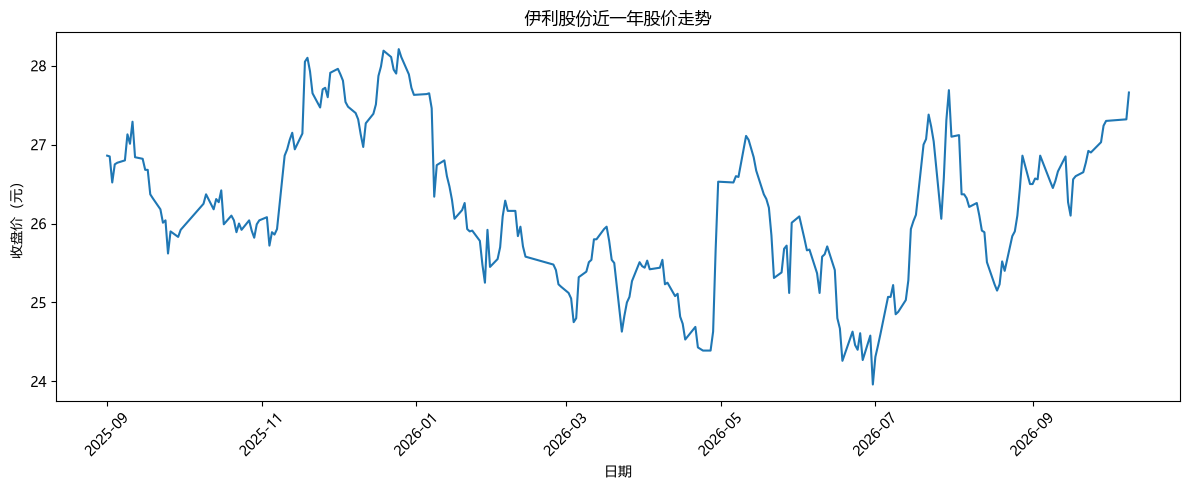

In [7]:
# 图1：近一年股价走势
plt.figure(figsize=(12, 5))
plt.plot(df_price.index, df_price['close'], color='#1f77b4')
plt.title('伊利股份近一年股价走势')
plt.xlabel('日期')
plt.ylabel('收盘价（元）')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

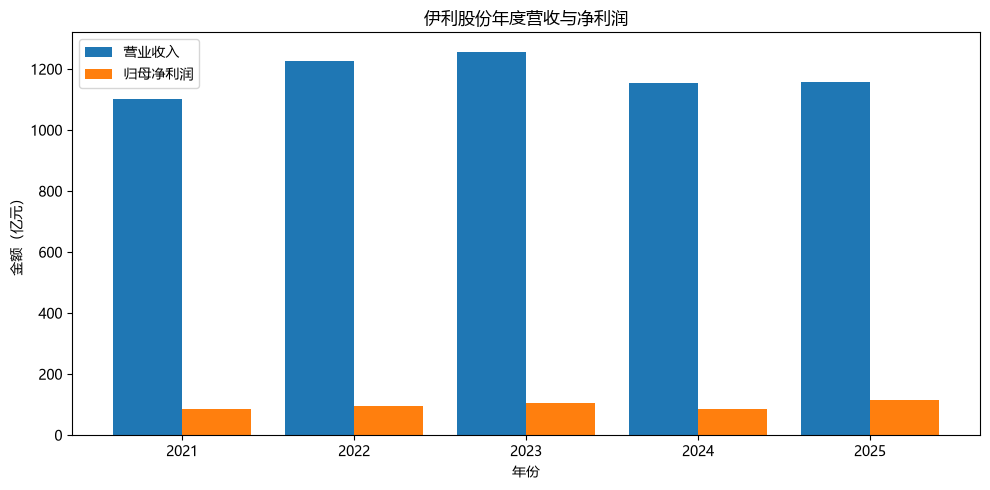

In [8]:
# 图2：年度营收与净利润对比
years = df_result['报告期'].dt.year.astype(str)
x = range(len(years))

plt.figure(figsize=(10, 5))
plt.bar([i - 0.2 for i in x], df_result['营业收入(亿)'], 0.4, label='营业收入', color='#1f77b4')
plt.bar([i + 0.2 for i in x], df_result['归母净利润(亿)'], 0.4, label='归母净利润', color='#ff7f0e')
plt.title('伊利股份年度营收与净利润')
plt.xlabel('年份')
plt.ylabel('金额（亿元）')
plt.xticks(x, years)
plt.legend()
plt.tight_layout()
plt.show()

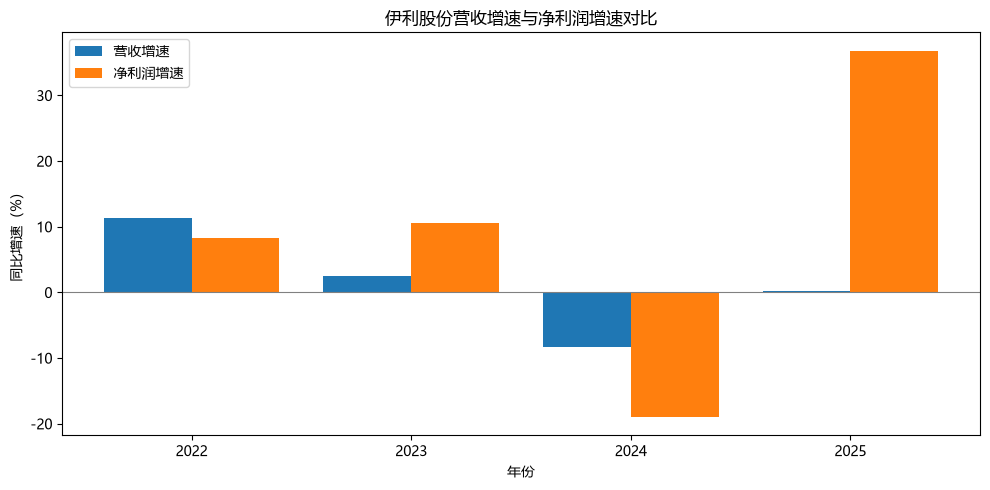

In [9]:
# 图3：营收增速 vs 净利润增速
rev_growth = df_result['营业收入'].pct_change().dropna() * 100
profit_growth = df_result['归母净利润'].pct_change().dropna() * 100
growth_years = df_result['报告期'].dt.year.astype(str)[1:]

x = range(len(growth_years))
plt.figure(figsize=(10, 5))
plt.bar([i - 0.2 for i in x], rev_growth, 0.4, label='营收增速', color='#1f77b4')
plt.bar([i + 0.2 for i in x], profit_growth, 0.4, label='净利润增速', color='#ff7f0e')
plt.axhline(y=0, color='gray', linewidth=0.8)
plt.title('伊利股份营收增速与净利润增速对比')
plt.xlabel('年份')
plt.ylabel('同比增速（%）')
plt.xticks(x, growth_years)
plt.legend()
plt.tight_layout()
plt.show()

# 第五部分：研究结论与经验总结

## 研究结论

基于以上数据，我的判断是：伊利的"收入"是稳的，但"利润"确实会跟着成本波动，忽高忽低。这种波动更多是行业周期造成的，不是公司经营出了大问题。

原因是：营业收入一直在稳步增长，说明伊利的牛奶、酸奶还是卖得动的，市场份额没有被别人抢走。但净利润的波动明显比营收大得多——收入涨一点或跌一点，利润的波动被放大好几倍。这说明利润对成本的变化非常敏感。

结合乳制品行业的特点，最合理的解释是原奶价格的周期性变化。2024年净利润大幅下滑（约-19%），很可能是因为那段时间原奶成本相对较高，或者伊利加大了销售费用的投入；2025年利润反弹，则可能是成本压力缓解带来的。

所以，伊利利润的"忽高忽低"是阶段性的、可以解释的，不代表它赚钱的能力变差了。作为一家卖日常消费品的大公司，收入的稳定性是它的底色，利润的波动更像是跟着行业周期在起伏。

## 经验总结


数据搜集和分析比想象中简单，但"看什么指标"需要动脑子。不过几行代码就能拿到数据，真正花时间的是想清楚：要回答"利润为什么波动"这个问题，需要对比营收和利润的变化，而不是只看利润本身。

"增速"比"绝对值"更能说明问题。 伊利的净利润绝对值看起来在增长（2021年的87亿到2025年的116亿），但把每年的增速算出来，就能看到中间的"坑"。这个习惯以后看财报的时候也可以用。

数据背后的行业逻辑很重要。 如果只看数字，可能会觉得伊利"忽好忽坏"。但结合乳制品行业原奶周期的背景，这个波动就有了合理的解释。数据是工具，理解业务才是目的。